In [4]:
import sklearn
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

**Please write your name below** (in case the file names get mixed up)

Adel Sahuc

# Clustering

## Probably not K-Means

Remember that in lab 1, we stumbled upon a dataset with two clearly identified clusters, but which K-Means could not usefully separate, because the delimitations were non-linear.

In [5]:
from sklearn import datasets
X_moons, y_moons = sklearn.datasets.make_moons(n_samples=200, shuffle=True, noise=0.05, random_state=42)

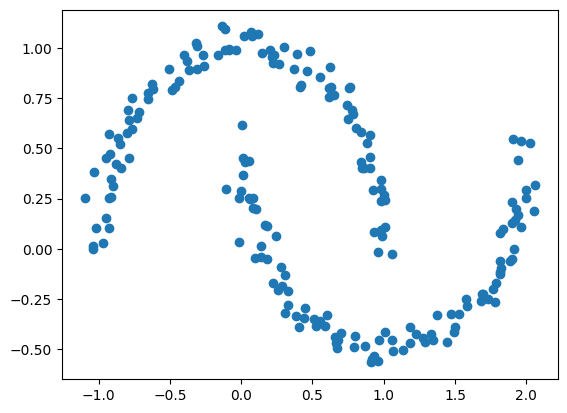

In [6]:
plt.scatter(X_moons[:,0], X_moons[:,1])
plt.show()

**Use a suitable clustering algorithm to assign each point to a cluster. Plot the result.**

You can consider that we know in advance how many clusters we want to obtain. You can (and maybe should) use an existing implementation.

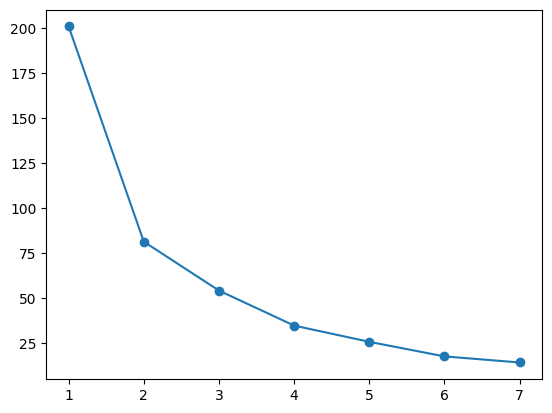

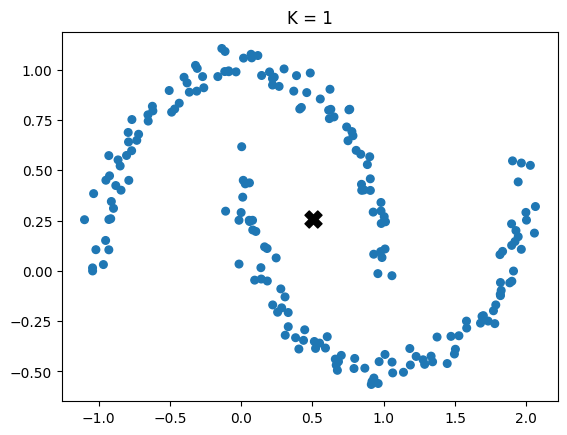

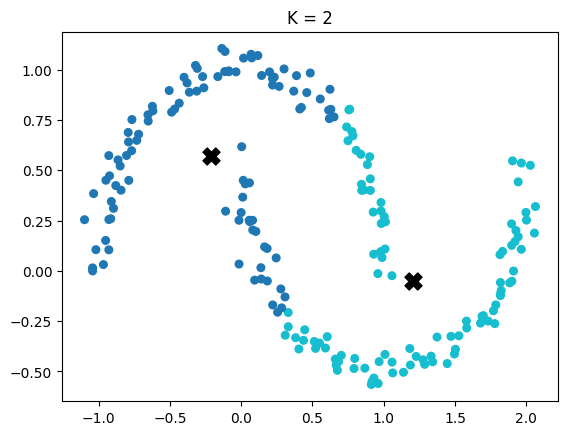

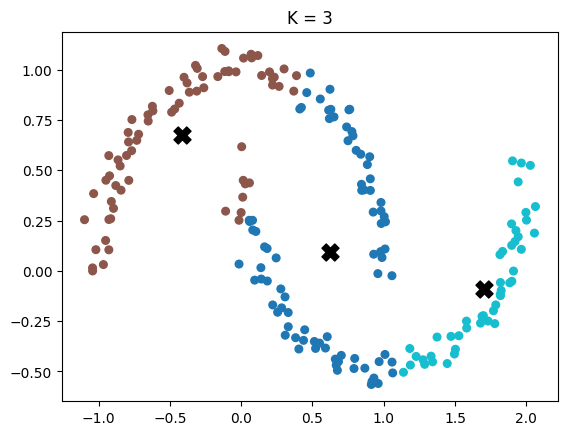

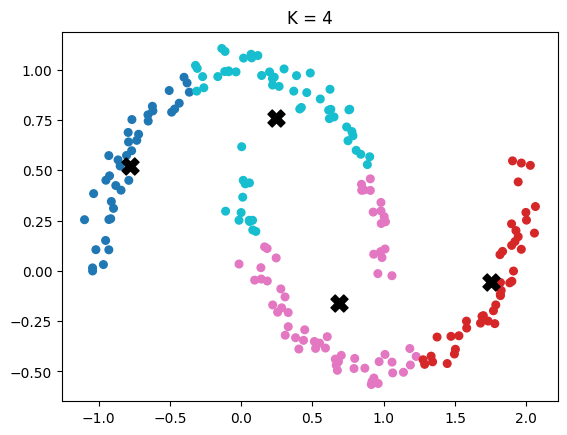

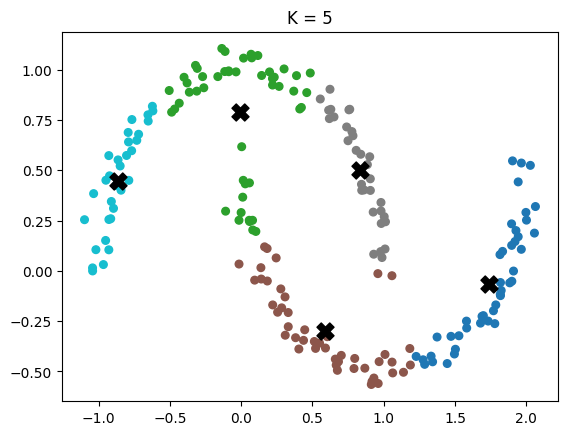

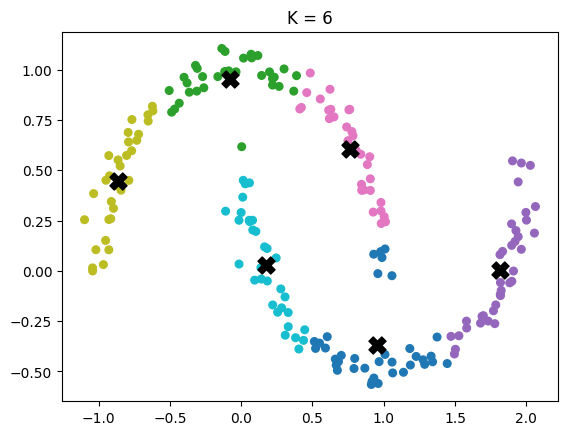

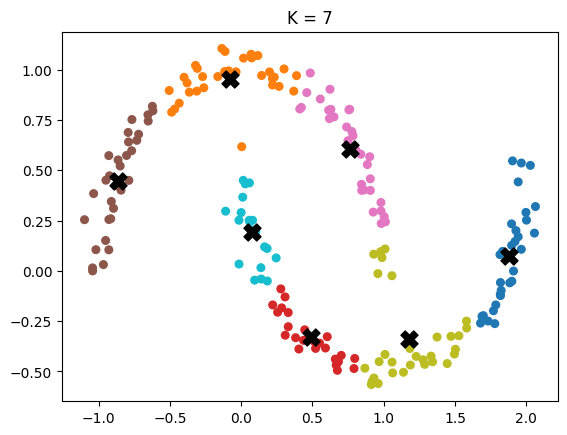

In [7]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

k_values = range(1, 8) # different k values
inertias = []

for k in k_values:

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_moons)

    inertias.append(kmeans.inertia_)


plt.plot(k_values, inertias, marker='o')
plt.xticks(k_values)
plt.show()

for k in range(1, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_moons)
    plt.scatter(X_moons[:, 0], X_moons[:, 1], c=km.labels_, cmap='tab10', s=30)
    plt.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='black', marker='X', s=150)
    plt.title(f"K = {k}")
    plt.show()

"""
Looking at the elbows in the first graph here I would say that there are two big elbows. One at 2 and one at 4.
Both 2 and 4 are both respectable answers depending on how many clusters are expected/wanted dependiing on what the data is.
"""

# Dimensionality reduction

## Data visualization

We will now use the MNIST dataset. It consists of 28x28 pixels images of handwritten digits, for total of 784 dimensions.

We could fetch the whole dataset with

In [10]:
# digits = fetch_openml(name='mnist_784')

However, we are not going to need the full dataset for this lab. Instead, let's load a prepared sample of 1000 handwritten digits.

Dataset can be downloaded here: https://drive.google.com/file/d/1c83lv_Xlw1-bXlWtMXxO6M1qmar3ErkW/view?usp=drive_link

In [11]:
# Load the dataset
# make sure that the file is located in the same folder as the notebook
# (or change the path)
digits = np.load("mnist.npz")

In [12]:
# Define features as X and targets as y
X_digits, y_digits = digits["data"], digits["target"]
print(f"Matrix has dimension {X_digits.shape}")

Matrix has dimension (1000, 784)


Let's display some of the digits.

Conveniently, the first 10 samples are 0, 1, 2, ..., 9. The rest are in a random order.

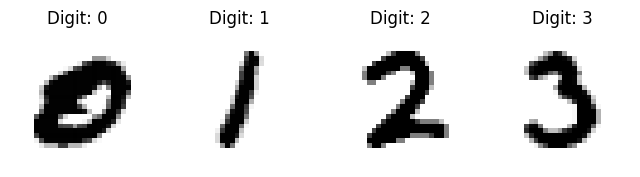

In [13]:
# Display the first 4 digits
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(8, 3)) # Create 4 subplots on 1 row
for ax, x, y in zip(axes, X_digits, y_digits):
    ax.set_axis_off() # do not display scale on axes
    img = x.reshape(28,28) # resize 784 dim vector as an 28 x 28 array of pixels
    ax.imshow(img, cmap=plt.cm.gray_r, vmin=0, vmax=1) # display image in gray scale, with values from 0 to 1
    ax.set_title(f"Digit: {y}")

**Apply PCA to obtained a representation $\mathbf{Z}$ of the data in 2 dimensions.**

You may use the implementation from scikit-learn.

In [18]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

pca_2_dim_digits = pca.fit_transform(X_digits)

print(f"Original shape: {X_digits.shape}")
print(f"Reduced shape (Z): {pca_2_dim_digits.shape}")

Original shape: (1000, 784)
Reduced shape (Z): (1000, 2)


/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

**Plot the corresponding representation. Display the digits as different colors.**

Use a scatter plot. Optionnaly, you may print a legend to know which color correspond to which digit.

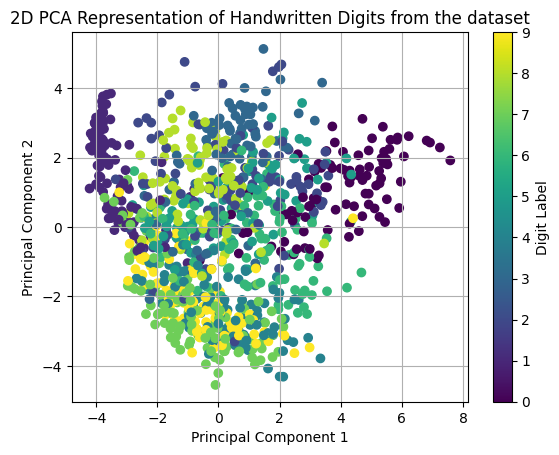

In [21]:
scatter = plt.scatter(pca_2_dim_digits[:, 0], pca_2_dim_digits[:, 1], c=y_digits)

cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label('Digit Label')

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('2D PCA Representation of Handwritten Digits from the dataset')
plt.grid(True)
plt.show()

**Are there any hyper-parameters? If yes, which one(s) did you choose?**.

Yes for PCA the biggest hyperparameters are the number of components. In this case we used two. Other hyperparameters such as to whiten (to normalize variance accross variables), the exact SVD solver, and random state I just used the deafaults. THere are a few more hyperparametesr that re more advanced that I didn't play aroudn with/look into too much.

**Now do the same things with t-SNE instead.**

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

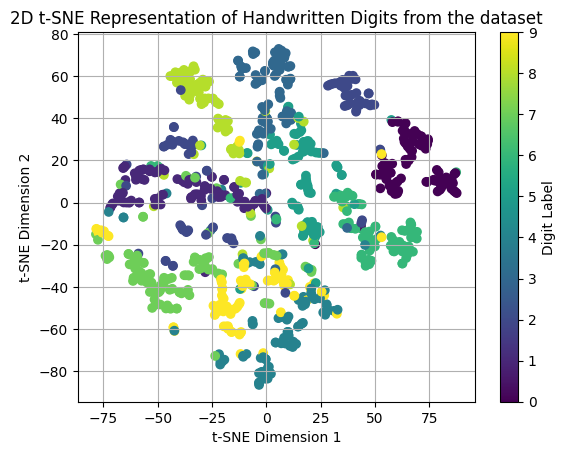

In [27]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42, perplexity=5)
tsne_2_dim_digits = tsne.fit_transform(X_digits)

scatter = plt.scatter(tsne_2_dim_digits[:, 0], tsne_2_dim_digits[:, 1], c=y_digits)

cbar = plt.colorbar(scatter, ticks=range(10))
cbar.set_label("Digit Label")

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("2D t-SNE Representation of Handwritten Digits from the dataset")
plt.grid(True)
plt.show()

**Are there any hyper-parameters? If yes, which one(s) did you choose?**.

Yes there are. There are hyperparameters for number of dimensions, random state and perplexity (number of nearest neighbors used in the algorithm). There are several more but I didn't feel a need to do them including early_exageration (the tighness of the clusters & the space between clusters), learning_rate, max_iter, n_iter_without_progress, min_grtad_norm (for gradient below threshold stop), metric (the default euclidean made sense here) and quite a few more.

I chose random state and perpelxity beacuse fistly it states in teh sklearn documentation that t-sne may not be strictly convex and so there may bee various solutions depending on the initial 'starting' point, so I though it would be important to set a fixed random state to ensure clear reproducibility. The directions called for two dimension so two were used. Perplexity was fun to play with, the docs said a lower perplexity may be better for smaller datasets and I visually thought that it may be true and so that is why I picked a perplexity of 5.

**Does one algorithm seem to give "better" results than the other? If yes, which one? Why may that be?** 

I think t-sne did better in making the digits unique in different spaces accross two dimensions. It may matter as if the dimensionality reduction does a good job making the classification data differentaible (ie more spread apart) it makes it easier for the classifier to classify correctly since each target is more easily seperatable.

**Just for fun, let's do the same thing with a 3rd dimensionality reduction method. You may pick the one you please.**

Maybe have a look at this documentation: https://scikit-learn.org/dev/modules/manifold.html#manifold-learning

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

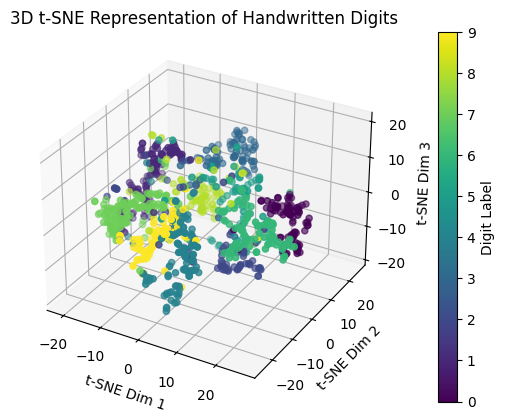

In [34]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

tsne_3d = TSNE(n_components=3, random_state=42, perplexity=5)
tsne_3_dim_digits = tsne_3d.fit_transform(X_digits)

fig = plt.figure()
ax = fig.add_subplot(projection="3d")

scatter = ax.scatter(
    tsne_3_dim_digits[:, 0],
    tsne_3_dim_digits[:, 1],
    tsne_3_dim_digits[:, 2],
    c=y_digits,
)

cbar = fig.colorbar(scatter, ticks=range(10), ax=ax, pad=0.1)
cbar.set_label("Digit Label")

ax.set_xlabel("t-SNE Dim 1")
ax.set_ylabel("t-SNE Dim 2")
ax.set_zlabel("t-SNE Dim 3")
ax.set_title("3D t-SNE Representation of Handwritten Digits")
plt.show()

## Data generation

We have seen that we are able to identify some structure in the data. Now let's use this structure to generate new samples!

We will generate some handwritten '5s'.

Since there aren't that many 5s in the initial dataset with 1000 samples, let's load some additional images of 5.

In [35]:
X_five = digits["fives"]
print(f"Matrix has dimension {X_five.shape}")

Matrix has dimension (6313, 784)


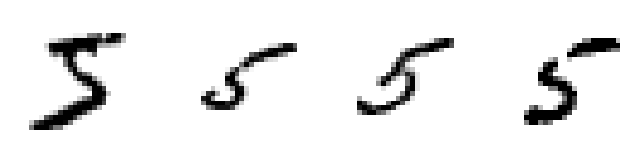

In [36]:
# Display the first 4 fives
_, axes = plt.subplots(nrows=1, ncols=4, figsize=(8, 3)) # Create 4 subplots on 1 row
for ax, x in zip(axes, X_five):
    ax.set_axis_off()
    img = x.reshape(28,28)
    ax.imshow(img, cmap=plt.cm.gray_r, vmin=0, vmax=1)

**What does the "average" 5 look like?**

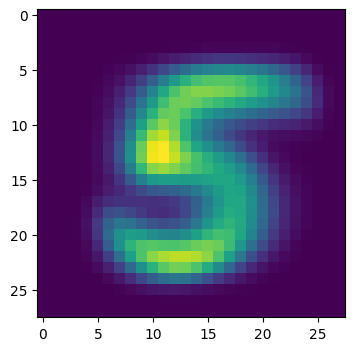

In [42]:
mean_five = X_five.mean(axis=0)
plt.figure(figsize=(4, 4))
plt.imshow(mean_five.reshape(28, 28))
plt.show()

To help you make a hopefully clear link between the slides from the lecture and an actual implementation of PCA, I provided a **commented implementation** of PCA that is reasonably close to what we covered in class. You will find it at the end of this notebook.

The name of the functions and attributes I use are the same as the ones from scikit-learn, to not induce any confusion.

You are free to use either this version, or the one from scikit-learn while using this as a reference to what is happening behind the scene. You are also free to not look at it at all, do as you please.

**Apply PCA to obtained a representation $\mathbf{Z}$ of the data in 2 dimensions. Then, apply the reverse transformation to reconstruct $\hat{\mathbf{X}}$ in 784 dimensions from its low dimension representation.**

**Important**: you need to reconstruct $\hat{\mathbf{X}}$ *from* $\mathbf{Z}$.

In [43]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
z = pca.fit_transform(X_five)
X_hat = pca.inverse_transform(z)

print(f"Original shape: {X_five.shape}")
print(f"2D representation z shape: {z.shape}")
print(f"Reconstructed X_hat shape: {X_hat.shape}")

Original shape: (6313, 784)
2D representation z shape: (6313, 2)
Reconstructed X_hat shape: (6313, 784)


/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

**Display some samples from the original dataset, along with some reconstructed samples**

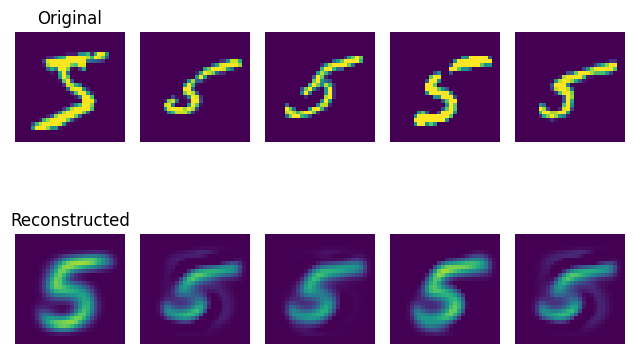

In [44]:
n_samples = 5
fig, axes = plt.subplots(2, n_samples)

for i in range(n_samples):
    axes[0, i].imshow(X_five[i].reshape(28, 28), vmin=0, vmax=1)
    axes[0, i].axis("off")
    if i == 0:
        axes[0, i].set_title("Original")

    axes[1, i].imshow(X_hat[i].reshape(28, 28), vmin=0, vmax=1)
    axes[1, i].axis("off")
    if i == 0:
        axes[1, i].set_title("Reconstructed")

plt.tight_layout()
plt.show()

**What do you notice?**

Because we compressed a lot of dimensions (784) down to just 2 principal components, we discarded a lot of the variance such as sharp edges stroke thickness, the picking up and putting down of the writing instrument ie discontinous lines. This makes the reconstructed ones look blurry, and smoothed out. 

Interestingly there is noise in the void. I think this is because not all of the 5's are in originals are in the same positioning so there is a faint overlay of large eigenvalues of 5's that were made in different positions in the background which is especially visible in the 2nd and 5th. This glossy background matches a smiliar shape as the first so it may be that 'type' of 5 shape/orientation that is making large eigenvalues that manifest in the background here.

**Now do the same, but this time keeping 10 dimensions (i.e. 10 principal components), then 50, then 200 (out of 784).**

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

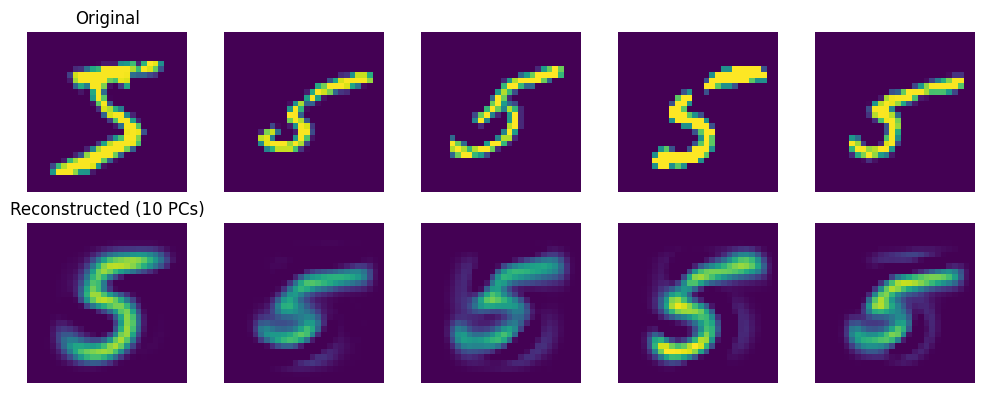

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

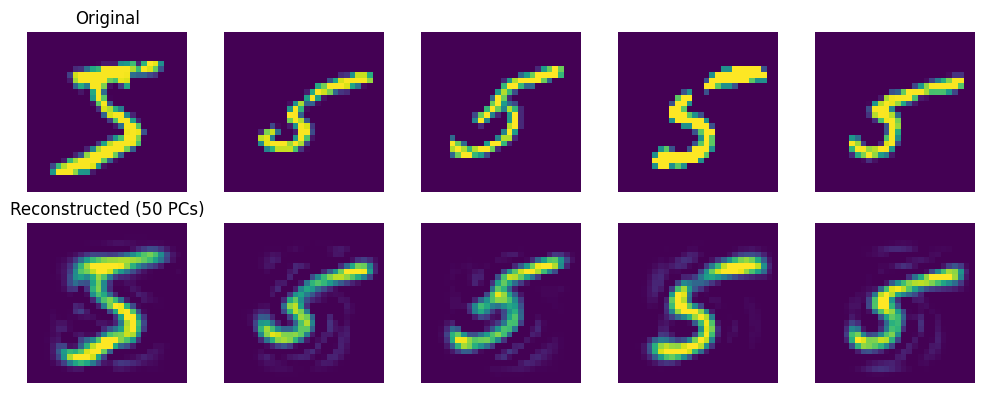

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

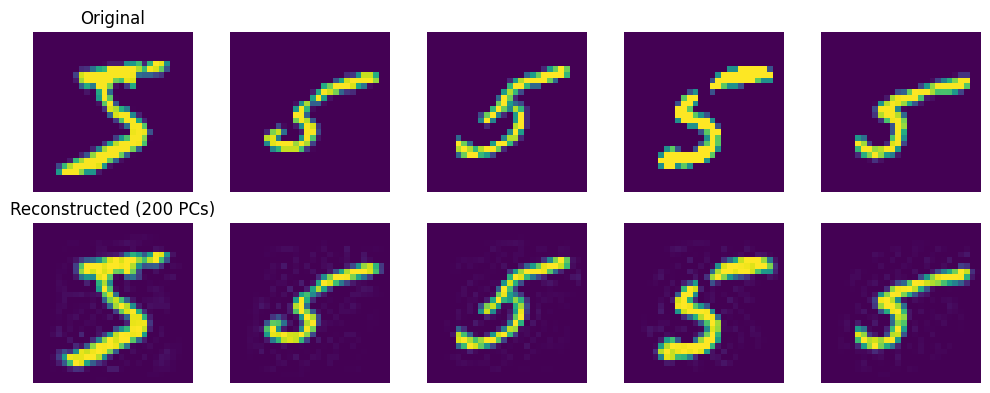

In [49]:
n_components_list = [10, 50, 200]
num_display = 5
for n in n_components_list:
    pca = PCA(n_components=n)
    z = pca.fit_transform(X_five)
    X_hat = pca.inverse_transform(z)

    fig, axes = plt.subplots(2, num_display, figsize=(10, 4))
    for i in range(num_display):
        axes[0, i].imshow(X_five[i].reshape(28, 28), vmin=0, vmax=1)
        axes[0, i].axis("off")
        if i == 0:
            axes[0, i].set_title("Original")

        axes[1, i].imshow(X_hat[i].reshape(28, 28), vmin=0, vmax=1)
        axes[1, i].axis("off")
        if i == 0:
            axes[1, i].set_title(f"Reconstructed ({n} PCs)")

    plt.tight_layout()
    plt.show()

**Do you notice a trend?**

Yes, I notice that as the nubmer of PC's increases, the recreations become more and more liek the original, to the pont that at 200 PC's the original and reconstructed look incredibly similiar. Ther eis alos a lot less of this glossyness/noise as the number of PC's go up. The conclusion is as the number of PC's increases the ammount of 'variance' or 'uniqueness' of each reconstruction increases until the reconstruction and the original look identical (and probably are identical when the number of PC's = the number of original parameters).

This can actually be quantified with *explained variance*: recall from class that the first principal component corresponds to the axis with the largest variance, corresponding to the largest eigenvalue. But there may still be some variance left in other directions in the data, that would require other principal components.
The second principal component is the one with the second largest variance. Using this component in addition to the first one enables us to capture, or "explain", a bit more of the total variance of the data. Adding the third principal component lets us explain even more variance, and so on.

We can consider that the total variance of the data is the sum of the variances along all axes. By summing the variance of all principal components and dividing by the total variance, we can thus measure what percentage of the total variance we can explain with a given number of principal components.

In [50]:
# Measuring the explained variance for different numbers of principal components
for P in [2,10,50,200]:
    pca = PCA(n_components=P)
    Z = pca.fit_transform(X_five)
    # we use the explained variance method:
    # this gives us the explained variance for each of our P components,
    # normalized so that the total variance for P=D would be 1.
    explained_variance = pca.explained_variance_ratio_.sum()
    print(f"Explained variance with {P} components: {explained_variance:.3f}")

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

Explained variance with 2 components: 0.262
Explained variance with 10 components: 0.554


/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = qr_normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: overflow encountered in matmul
  Q, _ = qr_normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: invalid value encountered in matmul
  Q, _ = qr_normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:533: RuntimeWarning: divide by zero encountered in matmul
  B = Q.T @ M
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:533: RuntimeWarning: overflow encountered in matmul
  B = Q.T @ M
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:533: RuntimeWarning: invalid value encountered in matmul
  B = Q.T @ M
/Volumes/CrucialX6/Home/

Explained variance with 50 components: 0.851


/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = qr_normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: overflow encountered in matmul
  Q, _ = qr_normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:340: RuntimeWarning: invalid value encountered in matmul
  Q, _ = qr_normalizer(A @ Q)


Explained variance with 200 components: 0.976


/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:533: RuntimeWarning: divide by zero encountered in matmul
  B = Q.T @ M
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:533: RuntimeWarning: overflow encountered in matmul
  B = Q.T @ M
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:533: RuntimeWarning: invalid value encountered in matmul
  B = Q.T @ M
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:547: RuntimeWarning: divide by zero encountered in matmul
  U = Q @ Uhat
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:547: RuntimeWarning: overflow encountered in matmul
  U = Q @ Uhat
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:547: RuntimeWarning: invalid value encountered in matmul
  U = Q @ Uhat


As you can see, using only 2 components only captures about a quarter of the total variance. This explains why reconstructed fives are quite different: we are missing quite a lot of information.

On the other hand, with 200, we capture 97%+ of the variance: the reconstructed fives are almost identical to the original ones. But we have "reduced the dimension a lot less", since we still have 200 dimensions in our reduced dataset.

Finally, using 784 components (as many as the initial dimension of the data) would enable us to have 100% explained variance, but at the cost of not having reduced the dimension of the data at all.

**Find the number of components needed to explain at least 50% of the variance.**

In [51]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.50)
pca.fit(X_five)

print(f"Number of components needed for 50% variance: {pca.n_components_}")

Number of components needed for 50% variance: 8


Remember that the principal components should be independant (or more exactly, uncorrelated). We can therefore sample some data independently along each axis, and combine the sampled vectors to approximately match the distribution of the dataset.

**Using a vector space with the same number of dimensions, generate vectors along the principal components independently. Then, use these reduced dimension representations to reconstruct samples in the original image space.**

This is probably the hardest question you have met in this class (so far). Do not hesitate to ask for help.

Hint: if you use the scikit-learn implementation, there is a parameter whose default value should be changed to ensure that your coordinates z in principal component space have unit variance.

You may want to check the doc: https://scikit-learn.org/dev/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA
    
In general, it is a good habit to look at the documentation of the implementations we are using, to ensure that everything behaves as we expect by default, and that we are not missing something important.

In [59]:
n_components = 50
pca = PCA(n_components=n_components, whiten=True) # should I use whiten ?? so latent cordinates have zero mean so unit variance is same ? 
# I am finding the results to be slightly more better when whiten=True
pca.fit(X_five)


# here sempling synthetic latent vectors
n_generated=5
z_samples = np.random.randn(n_generated, n_components)

# now reconstruction
X_generated = pca.inverse_transform(z_samples)

/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:335: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normalizer(A @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: divide by zero encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: overflow encountered in matmul
  Q, _ = normalizer(A.T @ Q)
/Volumes/CrucialX6/Home/dev-env/lib/python3.9/site-packages/sklearn/utils/extmath.py:336: RuntimeWarning: invalid value encountered in matmul
  Q, _ = normaliz

**Plot the resulting images.**

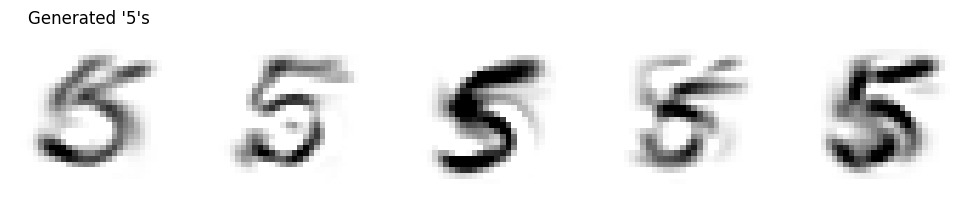

In [60]:
fig, axes = plt.subplots(1, n_generated, figsize=(10, 2))
for i in range(n_generated):
    axes[i].imshow(X_generated[i].reshape(28, 28), cmap=plt.cm.gray_r, vmin=0, vmax=1)
    axes[i].axis("off")
    if i == 0:
        axes[i].set_title("Generated '5's")

plt.tight_layout()
plt.show()

**Are all the generated numbers indistinguishable from the original numbers?**

***Optional: what may be the reason?***

I mean they look very different from the original handwritten ones. This is probably because PCA is purely linear, the ways to draw and understand the letter 5 are not purely linear. I also think using the gaussian distribution assumption may be false here in this context, especially in visual images. The objective function (MSE) also doesn't help as it isn't able to do a sharp contrast since it favors smooth estimations instead of sharp 'hard' estimations. It would be interesting to choose a more 'extreme' objective function that is maybe quebic or exponential.

### Appendix: implementation of PCA

In [698]:
class MyPCA:
    """
    Implementation of PCA similar to scikit-learn
    """
    
    def __init__(self, n_components: int=2) -> None:
        """
        Init
        
        Args:
            n_components: P
        """
        self.n_components = n_components # P
        # Initialize empty attributes
        self.mean_ = None
        self.singular_values_ = None
        self.components_ = None
        
    def fit(self, X: np.ndarray) -> None:
        """
        Compute principal components from data
        
        Args:
            X: matrix of size N x D
            
        Result (stored):
            mean_: mu, vector of size D
            singular_values_: lambdas, vector of size P
            components_: matrix P, matrix of size P x D
        """
        N, D = X.shape
        self.mean_ = X.mean(axis=0) # mean (mu)
        X = X - self.mean_ # center: substract mean
        
        # Implementation from class: actually not robust
        """
        cov = X.T @ X / N # compute covariance matrix
        values, components = np.linalg.eig(cov) # get eigen values/vectors
        self.singular_values_ = np.sqrt(values)[:self.n_components] # keep first P singular values
        self.components_ = components.T[:self.n_components] # keep first P principal components
        """
        # Alternative implementation with SVD
        U, S, Vt = np.linalg.svd(X, full_matrices=False)  # U: N x N, S: min(N, D), Vt: D x D
        self.singular_values_ = S[:self.n_components] # keep first P singular values
        self.singular_values_ = self.singular_values_  / np.sqrt(N) # SVD does not normalize w.r.t. sample size
        self.components_ = Vt[:self.n_components] # keep first P principal components
    
    def transform(self, X: np.ndarray) -> np.ndarray:
        """
        Return coordinates of input in principal components basis
        
        Args:
            X: matrix of size N x D, coordinates in high-dim space
            
        Returns:
            Z: matrix of size N x P, coordinates in p.c. space
        """
        X = X - self.mean_ # center: substract mean
        Z = X @ self.components_.T  # project to p.c. basis
        return Z / self.singular_values_  # scale by singular values
    
    def inverse_transform(self, Z: np.ndarray) -> np.ndarray:
        """
        Maps back to high-dim space from coordinates in p.c. space
        
        Args:
            Z: matrix of size N x P, coordinates in p.c. space
                    
        Returns:
            X: matrix of size N x D, coordinates in high dim space
        """
        Z = Z * self.singular_values_ # "un-normalize" standard deviations
        X = Z @ self.components_ # compute coordinates in initial space
        return X + self.mean_ # "uncenter" by adding the mean
    
    def fit_transform(self, X: np.ndarray) -> np.ndarray:
        """
        Combination of fit and transform
        """
        self.fit(X)
        return self.transform(X)